# ROI_processing

In [158]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

In [51]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_hsfemur/data_processed.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures/hfemur'

# Cell type annotation

In [ ]:
sc.pl.umap(sdata['table'],color='leiden')

In [ ]:
sc.pl.spatial(sdata['table'],color='leiden',spot_size=80)

In [ ]:
fig=troutpy.pl.spatial_transcripts(sdata,scatter_size=0.6,boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type.pdf'))

In [48]:
sdata['xrna_metadata']

AnnData object with n_obs × n_vars = 0 × 274
    var: 'count', 'logfoldratio_over_noise', 'control_probe', 'p_value_Poisson', 'intracellular_proportion', 'extracellular_proportion', 'logfoldratio_extracellular', 'moran_I', 'moran_pval_norm', 'moran_var_norm', 'moran_pval_norm_fdr_bh', 'in_out_spearmanR', 'in_out_pvalue', 'proportion_of_colocalized', 'ks_stat', 'ks_pval', 'ad_stat', 'lr_stat', 'mean_displacement', '-log_ks_pval'

In [ ]:
troutpy.pl.metric_scatter(sdata,x='logfoldratio_over_noise',y='extracellular_proportion',size=10,linewidth=0,label_top_n_x=1,label_top_n_y=1,save=True,figures_path=saving_path,custom_plot_filename='scatter_extrcellular_logfoldratio.pdf')

We plot and visualize the expression of AQP3 and OGN

In [ ]:
fig=troutpy.pl.spatial_transcripts(sdata,scatter_size=0.6,boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type.pdf'))
fig=troutpy.pl.spatial_transcripts(sdata,scatter_size=4,gene_list=['AQP3'],boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type_AQP3.pdf'))

In [ ]:
fig=troutpy.pl.spatial_transcripts(sdata,scatter_size=3,gene_list=['OGN'],boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type_OGN.pdf'))

In [76]:
sdata['xrna_metadata'].var

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
LILRA4,2539,2.299047,False,0.000000e+00,0.250369,0.749631,-2.024450,0.001313,0.338143,0.000011,NaN,0.092004,1.787252e-14,0.026178
NegControlProbe_00034,243,-0.047417,True,0.000000e+00,0.486258,0.513742,-0.982787,-0.001649,0.314501,0.000011,NaN,NaN,NaN,0.000000
UPK3B,435,0.534867,False,0.000000e+00,0.272575,0.727425,-1.909400,-0.001871,0.290903,0.000011,NaN,0.086830,4.749606e-13,0.000000
CXCL12,0,-inf,True,1.000000e+00,1.000000,0.000000,inf,NaN,NaN,0.000011,NaN,NaN,NaN,NaN
KCNN3,2474,2.273113,False,0.000000e+00,0.357403,0.642597,-1.514460,-0.000594,0.435520,0.000011,NaN,0.099707,9.580742e-17,0.029851
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NegControlCodeword_0516,59,-1.462941,True,0.000000e+00,0.504202,0.495798,-0.910998,-0.000343,0.465778,0.000011,NaN,NaN,NaN,0.000000
UnassignedCodeword_0006,43,-1.779279,False,3.638168e-11,0.426667,0.573333,-1.223269,-0.001004,0.387014,0.000011,NaN,NaN,NaN,0.000000
NegControlCodeword_0521,25,-2.321603,True,1.876760e-03,0.561404,0.438596,-0.680945,-0.000234,0.478868,0.000011,NaN,NaN,NaN,0.000000
NegControlCodeword_0518,17,-2.707266,True,1.601529e-01,0.721311,0.278689,0.023172,-0.000337,0.466502,0.000011,NaN,NaN,NaN,0.000000


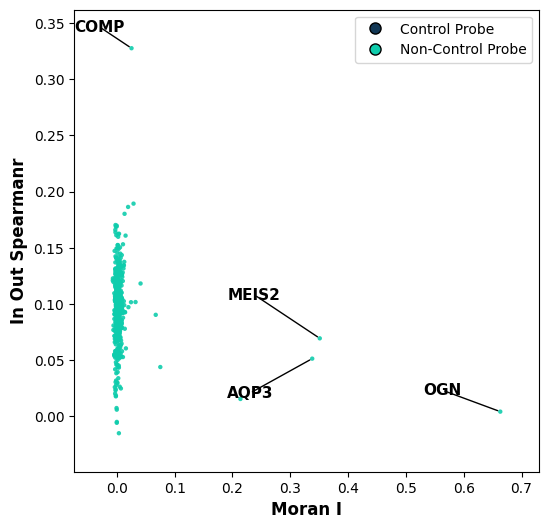

In [80]:
troutpy.pl.metric_scatter(sdata,x='moran_I',y='in_out_spearmanR',size=10,linewidth=0,label_top_n_x=3,label_top_n_y=1,save=True,figures_path=saving_path,custom_plot_filename='scatter_morani_inout.pdf')

In [ ]:
sc.tl.leiden(sdata['table'],resolution=1.2)
sc.pl.umap(sdata['table'],color='leiden')
sc.pl.spatial(sdata['table'],color='leiden',spot_size=100)
sc.tl.rank_genes_groups(sdata['table'],groupby='leiden')
sc.tl.dendrogram(sdata['table'],groupby='leiden')
sc.pl.rank_genes_groups_dotplot(sdata['table'],n_genes=6)
dict_anno={0:'Fibroblast 2',1:'Fibroblast 1',2:'Osteoblast',3:'SSPC_MPC',4:'Osteoblast',5:'Immune-rel. fibroblast',6:'Endothelial',7:'Adipocyte',8:'Osteoblast',
9:'B cell',10:'Myeloid',11:'Osteoclast',12:'Pre-osteoblast',13:'NK_Cells_T_cells'} # 13 could be T cell also

In [83]:
sdata['table'].obs['cell_type']=sdata['table'].obs['leiden'].astype(int).map(dict_anno)

In [ ]:
sdata['table'].uns['cell_type_colors'] = [
       "#0FCCAC",
            "#ED2073",
            "#123755",
            "#BFCE00",
            "#DF5AFF",
            "#FFFF7B",
            "#FC911D",
            "#E891B4",
            "red",
            "#37BEE2",
            "#790DB7",
            "#9CCE00",
            "#43FBFF",
            "#F7C894",
            "#BCBCBC",
            "#444444",
            "#096858",

]


sc.pl.umap(sdata['table'],color='cell_type')
sc.pl.spatial(sdata['table'],color='cell_type',spot_size=100)

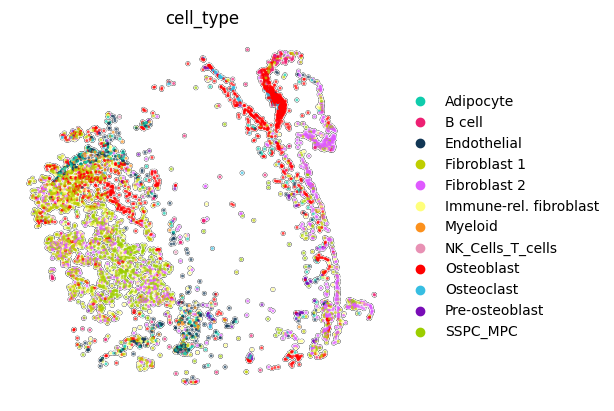

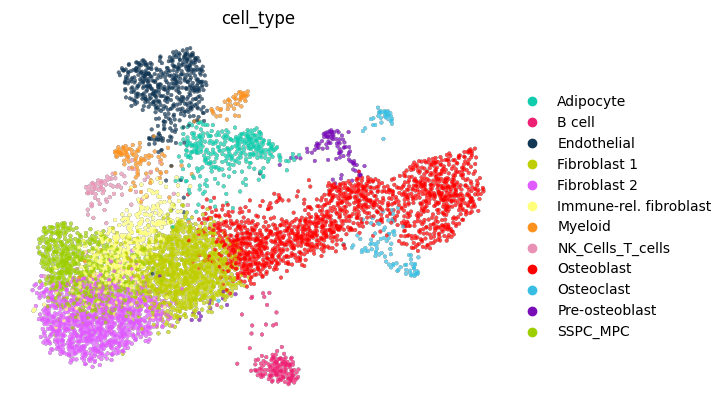

In [145]:
import matplotlib.pyplot as plt
import matplotlib

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.spatial(sdata['table'],color='cell_type',spot_size=80,add_outline=True,outline_width=(0.05,0.002),frameon=False,show=False)
plt.savefig(os.path.join(saving_path,'spatial_cell_type_map.pdf'))


import matplotlib.pyplot as plt
import matplotlib

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(sdata['table'],color='cell_type',s=30,add_outline=True,outline_width=(0.005,0.001),frameon=False,show=False)
plt.savefig(os.path.join(saving_path,'umap_cell_type_map.pdf'))

In [ ]:
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(sdata['table'],color='OGN',s=30,frameon=False,show=False,cmap='YlGnBu')
plt.savefig(os.path.join(saving_path,'umap_OGN.pdf'))

In [ ]:
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(sdata['table'],color='AQP3',s=30,frameon=False,show=False,cmap='YlGnBu')
plt.savefig(os.path.join(saving_path,'umap_AQP3.pdf'))

In [ ]:
import matplotlib.pyplot as plt
import matplotlib

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.tl.rank_genes_groups(sdata['table'],groupby='cell_type')
sc.tl.dendrogram(sdata['table'],groupby='cell_type')
sc.pl.rank_genes_groups_dotplot(sdata['table'],n_genes=3,show=False,cmap='Blues')
plt.savefig(os.path.join(saving_path,'dotplot_cell_type_map.pdf'))

# 2. Multivariate analysis

In [175]:
troutpy.pp.aggregate_urna(sdata,gene_key='gene',square_size=70,radius=70)

In [177]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=8)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=10)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=3)

In [ ]:
sc.pl.umap(adata, color="leiden", palette="tab20", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=80, show=False, ax=ax)
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="cell_type",spot_size=15,show=False, ax=ax,add_outline=True,outline_width=(0.1, 0.1))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=3)

In [183]:
adata

AnnData object with n_obs × n_vars = 9420 × 525
    obs: 'instance_id', 'region', 'n_genes', 'n_counts', 'leiden'
    var: 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'leiden_colors', 'dendrogram_leiden'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

In [194]:
sdata['table'].obs['type']='cell'
adata.obs['type']='uRNA_bin'

In [195]:
adata.obs['cell_type']='bin'

In [196]:
condata=sc.concat([sdata['table'],adata])

In [197]:
sc.pp.neighbors(condata, n_neighbors=10)
sc.tl.umap(condata)

In [ ]:
sc.pl.umap(condata,color=['type','cell_type'])
sc.pl.umap(adata, color=["leiden",'OGN','n_counts'], s=120,vmax='p99.5')

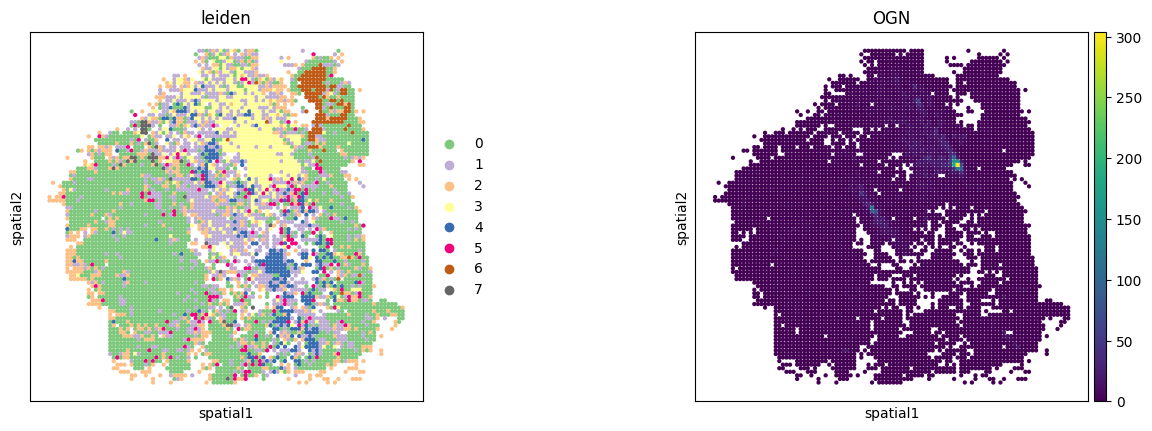

In [172]:
sc.pl.spatial(adata, color=["leiden",'OGN'], spot_size=120)

In [201]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)
troutpy.tl.factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")


{'Factor 1': ['OGN', 'CD79A', 'AIF1'], 'Factor 2': ['LILRA4', 'LPL', 'GPC1'], 'Factor 3': ['KCNN3', 'AIF1', 'DKK1'], 'Factor 4': ['CAVIN2', 'CD69', 'PDCD1'], 'Factor 5': ['SOST', 'MEPE', 'DMP1'], 'Factor 6': ['CLDN10', 'SMIM24', 'SDC1'], 'Factor 7': ['SLC4A1', 'CYP2F1', 'LRP6'], 'Factor 8': ['NMU', 'CD247', 'GALNT5'], 'Factor 9': ['MEIS2', 'TMEM52B', 'CD3E'], 'Factor 10': ['AQP3', 'NegControlCodeword_0515', 'CD28']}


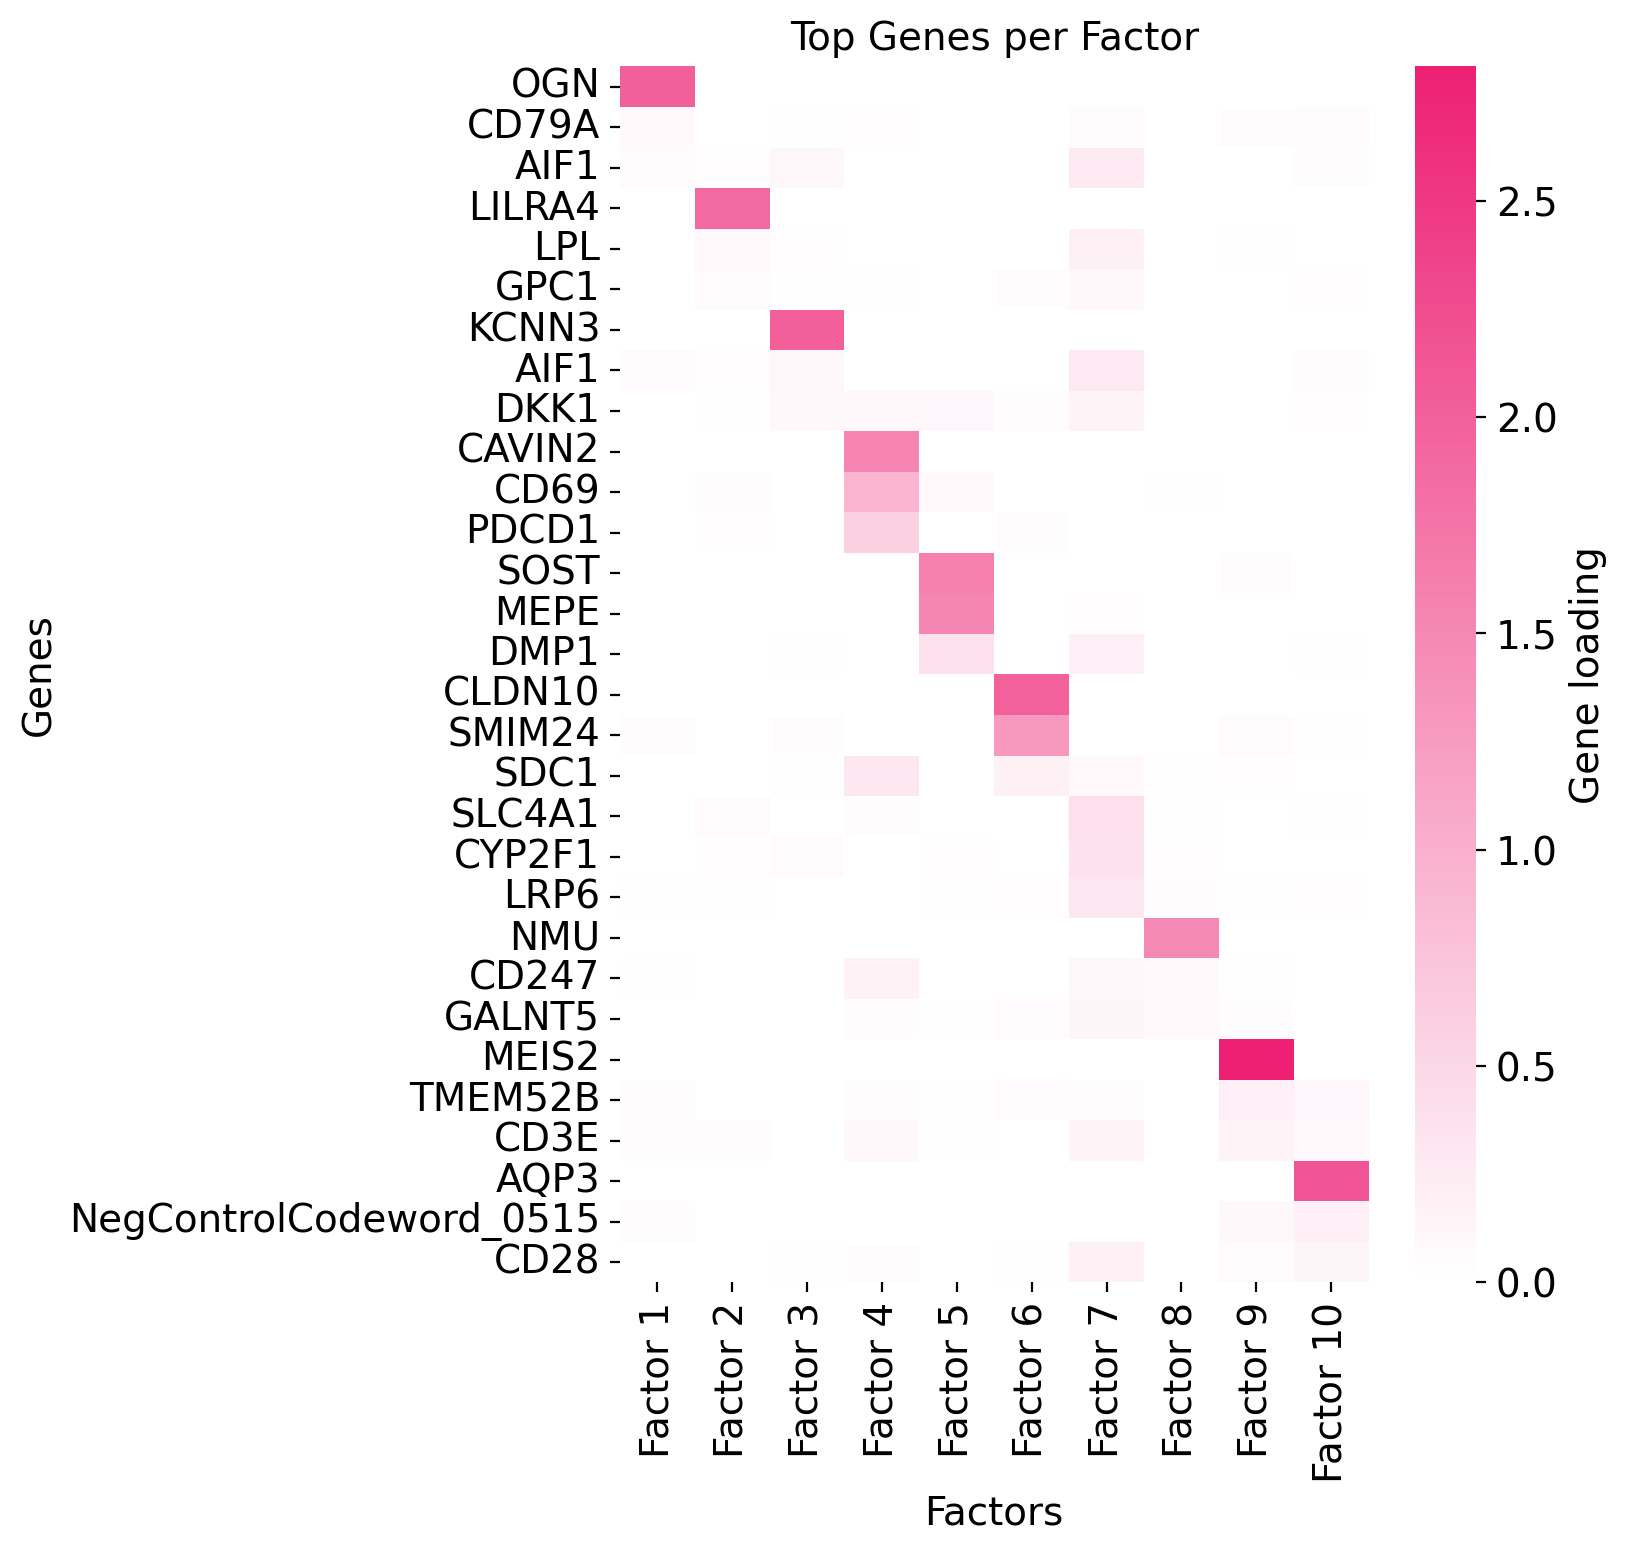

In [225]:
sc.set_figure_params(scanpy=True, dpi=100, dpi_save=100, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=3,figsize=(6,8),save=saving_path)

In [ ]:
sc.pl.umap(sdata['table'],color='cell_type')

In [218]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import troutpy as tp

def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12,complete_saving_path=None):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas_contrast")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, colorbar_loc=None,vmax='p99'
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.03,
            colorbar_loc=None, vmax='p99'
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    if complete_saving_path is not None:
        plt.savefig(complete_saving_path)
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=60,spot_size_extra=80,complete_saving_path=os.path.join(saving_path,'factors_urna_cells_bone.pdf'))

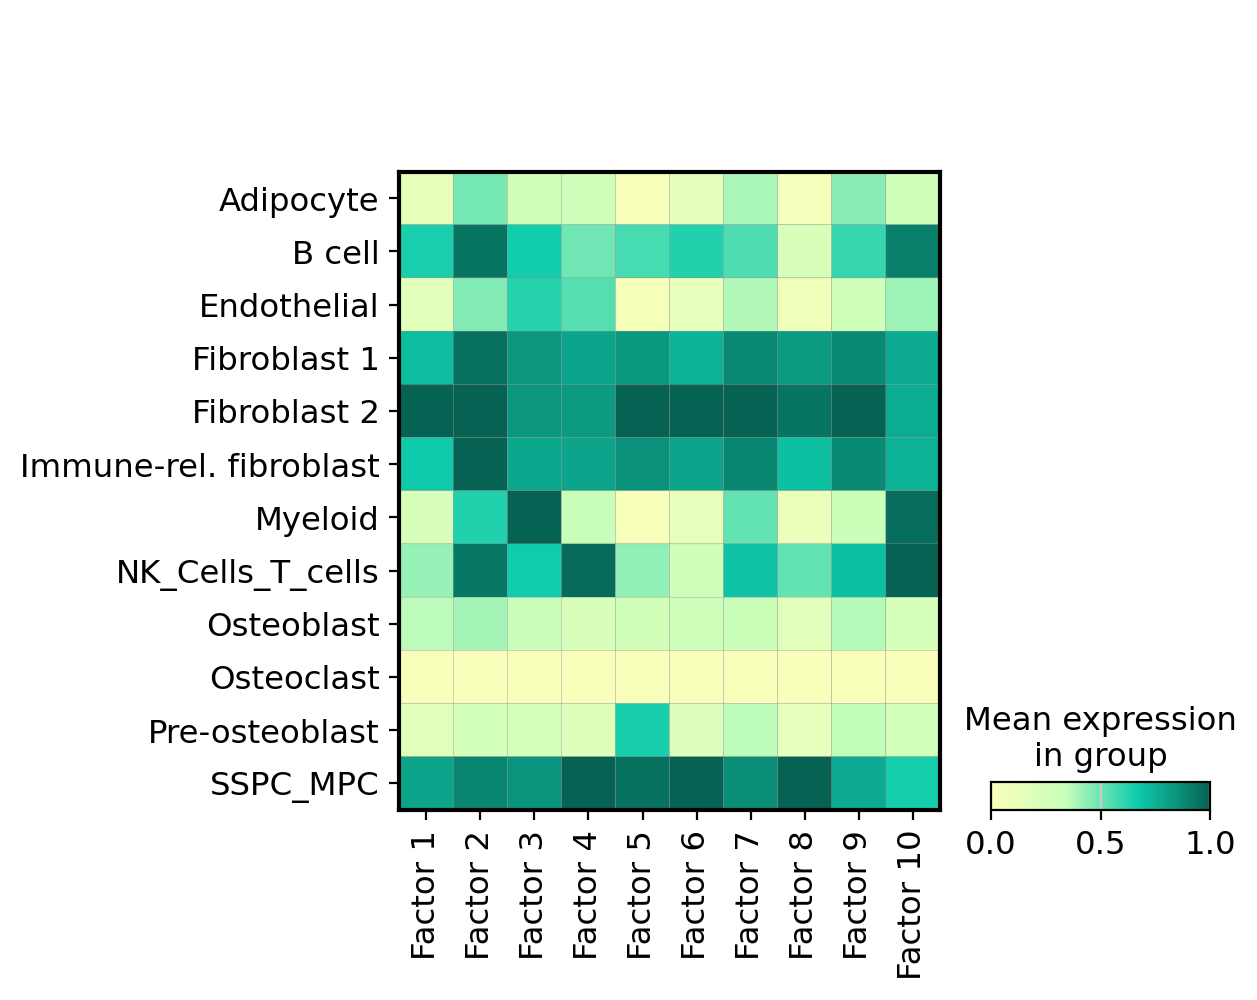

In [230]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap='Aquas_contrast', method="matrixplot",celltype_key='cell_type',standard_scale='var',show=False)
plt.savefig(os.path.join(saving_path, 'factors_scores_per_celltype_femur_norm.pdf'))

In [ ]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

In [ ]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


In [ ]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata,cluster_key="kmeans_distribution")

In [ ]:
cool_pattern_df = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["kmeans_distribution"] == 1.0]
selected_genes = cool_pattern_df.sort_values(by="count", ascending=False).index
troutpy.pl.gene_distribution_from_source(sdata, selected_genes[3:4])

## Target-score

In [ ]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.1,copy=False,celltype_key="leiden",gene_key='gene')

In [ ]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

## Communication strenght

In [ ]:
troutpy.tl.compute_communication_strength(sdata)

In [ ]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

In [ ]:
troutpy.pl.celltype_communication(sdata, kind="heatmap", celltype_key="cell type", figsize=(6, 6))

## Latent factor analysis

In [ ]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [ ]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")

In [ ]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

In [ ]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

In [ ]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [211]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

## Multimodal analysis

In [ ]:
sdata

### This is currently not working, to be fixed

In [ ]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

In [ ]:
get_transformation(sdata['morphology_focus'])

In [ ]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4,scale)

# Module analysis

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")